In [43]:
import pickle
import pandas as pd
import ast
import sys, os
from deep_translator import GoogleTranslator
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../..")))
from scripts.jaccard_similarity_bfmn import results_jaccard_similarities, plot_comparison

In [2]:
path_rassereno_bfmn = '/Users/emma/projects/cognoscolab/rassereno/out/analysis/bfmn'

## Latex Table

In [44]:
all_fmnts_features = pd.read_csv(f'{path_rassereno_bfmn}/fmnt_features.csv')

In [45]:
keyword_map = {
    "ansia": "anxiety",
    "benessere": "wellbeing",
    "computer": "computer science", 
    "esame": "exam",
    "fisica": "physics",
    "scuola": "school",
    "informatica": "computer science",
    "insegnante": "teacher",
    "matematica": "mathematics",
    "math": "mathematics",
    "professore": "professor",
    "scienza": "science",
    "scuola": "school",
    "scienziato": "scientist",
    "statistica": "statistics",
    "studente": "student",
    "universita": "university",
    "ricerca": "research",
    "voto": "grade",
}
sample_map = {
    "experts_2019": "Experts",
    "liceo_2019": "High Schoolers (South)",
    "liceo_2025/high_anxiety": "High-Anxiety High Schoolers (North)",
    "liceo_2025/low_anxiety": "Low-Anxiety High Schoolers (North)",
    "gpt_oss_high_school/high_anxiety": "GPT High-Anxiety High Schoolers",
    "gpt_oss_high_school/low_anxiety": "GPT Low-Anxiety High Schoolers",
    "physics_students_2025": "Physics Students",
    "gpt_oss_physics": "GPT Physics Students",
    "psychology_students_filtered/high_anxiety": "High-Anxiety Psychology Students",
    "psychology_students_filtered/low_anxiety": "Low-Anxiety Psychology Students",
    "gpt_oss_psychology/high_anxiety": "GPT High-Anxiety Psychology Students",
    "gpt_oss_psychology/low_anxiety": "GPT Low-Anxiety Psychology Students",
}

all_fmnts_features["keyword"] = all_fmnts_features["keyword"].map(keyword_map).fillna(all_fmnts_features["keyword"])

all_fmnts_features["Sample"]  = all_fmnts_features["Sample"].map(sample_map).fillna(all_fmnts_features["Sample"])

all_fmnts_features["Top Nodes"] = all_fmnts_features["Top Nodes"].apply(ast.literal_eval)

In [58]:
# collect all unique words
unique_words = list({w.capitalize() for lst in all_fmnts_features['Top Nodes'] for w in lst})

# smash them into one big string
joined = "\n".join(unique_words)

# translate in a single request
translated_blob = GoogleTranslator(source='it', target='en').translate(joined)

# split back into individual translations
translated_list = translated_blob.split("\n")

# stitch them back into a dict
translations = dict(zip(unique_words, translated_list))

In [59]:
all_fmnts_features['Top Nodes'] = all_fmnts_features['Top Nodes'].apply(
    lambda lst: [translations[w.capitalize()] for w in lst]
)

In [61]:
for keyword in all_fmnts_features['keyword'].unique():
    df_keyword = all_fmnts_features[all_fmnts_features['keyword'] == keyword].drop(columns=['keyword', '$d$']).to_latex(index=False,
                                                                                       escape=False,
                                                                                       float_format="%.2f", 
                                                                                       position="!hbpt", 
                                                                                       column_format ="C{4cm}ccccC{6.5cm}",
                                                                                       caption=f"Network features for the semantic frame of \"{keyword.capitalize()}\".",
                                                                                       label=f"tab:network_features_{keyword}",
                                                                                       )
    df_latex = df_keyword.replace(r"\begin{table}[!hbpt]", f"\\begin{{table}}[!hbpt]\n\\footnotesize\n\\centering")
    
    with open(f'{path_rassereno_bfmn}/fmnt_features_latex.txt', "a") as f:
        f.write(f"{df_latex}\n")

In [ ]:
keywords_rassereno_eng = ['mathematics', 'statistics', 'physics', 'science', 'computer', 'research', 'exam','grade', 'professor', 'teacher', 'scientist', 'school', 'university', 'anxiety', 'wellbeing']

cap_keywords = [w.capitalize().replace("'", "") for w in keywords_rassereno_eng]

dict_words = {'Experiment 1' : [cap_keywords[:6]], 
              'Experiment 2' : [cap_keywords[6:13]], 
              'Experiment 3' : [cap_keywords[13:]]}
df_words = pd.DataFrame.from_dict(dict_words)
df_words.to_latex()

"\\begin{tabular}{llll}\n\\toprule\n & Experiment 1 & Experiment 2 & Experiment 3 \\\\\n\\midrule\n0 & ['Mathematics', 'Statistics', 'Physics', 'Science', 'Computer', 'Research'] & ['Exam', 'Grade', 'Professor', 'Teacher', 'Scientist', 'School', 'University'] & ['Anxiety', 'Wellbeing'] \\\\\n\\bottomrule\n\\end{tabular}\n"

## Jaccard Similarity

In [19]:
# features_df = pd.read_json('/Users/emma/projects/cognoscolab/rassereno/notebooks/all_fmnts.json')
with open(f'{path_rassereno_bfmn}/all_bfmns.pkl', 'rb') as f:
    features = pickle.load(f)

## Psychology students

In [20]:
low_anx_psychology = results_jaccard_similarities(features, 'gpt_oss_psychology_low_anx', 'psychology_low_anx')

gpt_oss_psychology_low_anx:
matematica - ansia: 0.0136986301369863
matematica - esame: 0.03278688524590164
esame - ansia: 0.03508771929824561

psychology_low_anx:
matematica - ansia: 0.03731343283582089
matematica - esame: 0.07079646017699115
esame - ansia: 0.15315315315315314


In [32]:
high_anx_psychology = results_jaccard_similarities(features, 'gpt_oss_psychology_high_anx', 'psychology_high_anx')

gpt_oss_psychology_high_anx:
matematica - ansia: 0.014925373134328358
matematica - esame: 0.03571428571428571
esame - ansia: 0.038461538461538464

psychology_high_anx:
matematica - ansia: 0.12837837837837837
matematica - esame: 0.10810810810810811
esame - ansia: 0.13385826771653545


## High school students 2025

In [28]:
low_anx_high_school = results_jaccard_similarities(features, 'gpt_oss_high_school_low_anx', 'high_school_low_anx')

gpt_oss_high_school_low_anx:
matematica - ansia: 0.0
matematica - esame: 0.0
esame - ansia: 0.0

high_school_low_anx:
matematica - ansia: 0.04
matematica - esame: 0.054945054945054944
esame - ansia: 0.08860759493670886


In [29]:
high_anx_high_school = results_jaccard_similarities(features, 'gpt_oss_high_school_high_anx', 'high_school_high_anx')

gpt_oss_high_school_high_anx:
matematica - ansia: 0.0
matematica - esame: 0.03225806451612903
esame - ansia: 0.0

high_school_high_anx:
matematica - ansia: 0.0546875
matematica - esame: 0.07407407407407407
esame - ansia: 0.07920792079207921


## Fisica

In [30]:
physics = results_jaccard_similarities(features, 'gpt_oss_physics', 'physics')

gpt_oss_physics:
matematica - ansia: 0.0
matematica - esame: 0.0
esame - ansia: 0.0

physics:
matematica - ansia: 0.0196078431372549
matematica - esame: 0.029411764705882353
esame - ansia: 0.05128205128205128


In [33]:
all_results = {**low_anx_psychology,
               **high_anx_psychology,
               **low_anx_high_school,
               **high_anx_high_school,
               **physics}

In [34]:
rows = []
for k, (v1, v2, v3) in all_results.items():
    source = 'GPT-oss' if 'gpt' in k else 'Humans'
    group = k.replace('gpt_oss_', '').replace('_', ' ').title()
    rows.append({'group': group, 'source': source, 'comparison_1': v1, 'comparison_2': v2, 'comparison_3':v3})

df = pd.DataFrame(rows).sort_values('group')

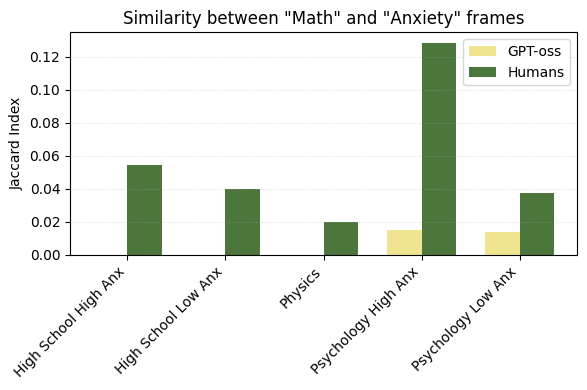

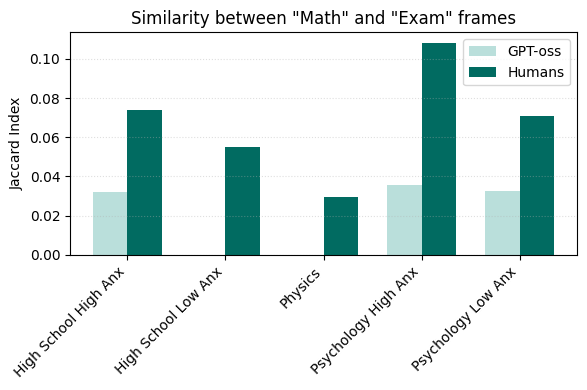

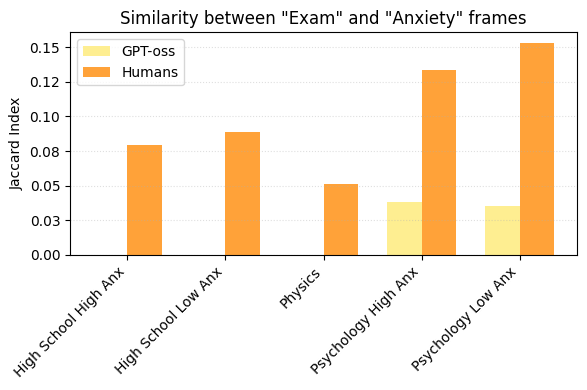

In [37]:
# Plot separately
plot_comparison(df, 'comparison_1', 'Similarity between "Math" and "Anxiety" frames', '#F0E491', '#4C763B')
plot_comparison(df, 'comparison_2', 'Similarity between "Math" and "Exam" frames','#BADFDB', '#016B61')
plot_comparison(df, 'comparison_3', 'Similarity between "Exam" and "Anxiety" frames','#FEEE91', '#FFA239')